# Machince Learning model

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

import matplotlib.pyplot as plt

from scipy.stats import randint

In [2]:
df = pd.read_csv('stroke_dataset_cleaned.csv')

df.head(10)

,Unnamed: 0,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
2,2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
3,3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1
4,4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1
5,5,53882,1,74.0,1,1,1,Private,0,70.09,27.4,never smoked,1
6,6,10434,0,69.0,0,0,0,Private,1,94.39,22.8,never smoked,1
7,7,60491,0,78.0,0,0,1,Private,1,58.57,24.2,Unknown,1
8,8,12109,0,81.0,1,0,1,Private,0,80.43,29.7,never smoked,1
9,9,12095,0,61.0,0,1,1,Govt_job,0,120.46,36.8,smokes,1


In [3]:
df = df.drop(columns=['Unnamed: 0'])

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4908 entries, 0 to 4907
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4908 non-null   int64  
 1   gender             4908 non-null   int64  
 2   age                4908 non-null   float64
 3   hypertension       4908 non-null   int64  
 4   heart_disease      4908 non-null   int64  
 5   ever_married       4908 non-null   int64  
 6   work_type          4908 non-null   str    
 7   Residence_type     4908 non-null   int64  
 8   avg_glucose_level  4908 non-null   float64
 9   bmi                4908 non-null   float64
 10  smoking_status     4908 non-null   str    
 11  stroke             4908 non-null   int64  
dtypes: float64(3), int64(7), str(2)
memory usage: 460.3 KB


In [5]:
(df['smoking_status'] == 'Unknown').sum()

np.int64(1483)

In [6]:
df['smoking_status'] = df['smoking_status'].map({
    'formerly smoked': 1,
    'never smoked': 0,
    'smokes': 1,
    'Unknown': 0
})

df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,1,1
1,31112,1,80.0,0,1,1,Private,0,105.92,32.5,0,1
2,60182,0,49.0,0,0,1,Private,1,171.23,34.4,1,1
3,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,0,1
4,56669,1,81.0,0,0,1,Private,1,186.21,29.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4903,14180,0,13.0,0,0,0,children,0,103.08,18.6,0,0
4904,44873,0,81.0,0,0,1,Self-employed,1,125.20,40.0,0,0
4905,19723,0,35.0,0,0,1,Self-employed,0,82.99,30.6,0,0
4906,37544,1,51.0,0,0,1,Private,0,166.29,25.6,1,0


In [7]:
features = ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
    'Residence_type', 'avg_glucose_level','bmi', 'smoking_status']

X = df[features]
y = df['stroke']

In [8]:
X

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,67.0,0,1,1,1,228.69,36.6,1
1,1,80.0,0,1,1,0,105.92,32.5,0
2,0,49.0,0,0,1,1,171.23,34.4,1
3,0,79.0,1,0,1,0,174.12,24.0,0
4,1,81.0,0,0,1,1,186.21,29.0,1
...,...,...,...,...,...,...,...,...,...
4903,0,13.0,0,0,0,0,103.08,18.6,0
4904,0,81.0,0,0,1,1,125.20,40.0,0
4905,0,35.0,0,0,1,0,82.99,30.6,0
4906,1,51.0,0,0,1,0,166.29,25.6,1


In [9]:
y

0       1
1       1
2       1
3       1
4       1
       ..
4903    0
4904    0
4905    0
4906    0
4907    0
Name: stroke, Length: 4908, dtype: int64

In [28]:
X_train, X_test , y_train , y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
rf = RandomForestClassifier(n_estimators=100,
    random_state=42,
    class_weight='balanced')

cv_scores = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring='f1'
)

print(f"Cross-validation F1 scores: {cv_scores}")
print(f"Mean F1 score: {cv_scores.mean():.4f}")

rf.fit(X_train_scaled, y_train)

Cross-validation F1 scores: [0.15686275 0.04166667 0.14285714 0.10714286 0.10344828]
Mean F1 score: 0.1104


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [37]:
y_pred_proba = rf.predict_proba(X_test_scaled)[:, 1]

threshold = 0.2

y_pred = (y_pred_proba >= threshold).astype(int)

In [38]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8207739307535642


In [39]:
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.8f}")
print(f"Recall: {recall:.8f}")
print(f"F1 Score: {f1:.8}")
print(f"ROC AUC: {roc_auc:.4f}")

Accuracy: 0.8208
Precision: 0.10588235
Recall: 0.42857143
F1 Score: 0.16981132
ROC AUC: 0.7432


Text(50.83333333333333, 0.5, 'True')

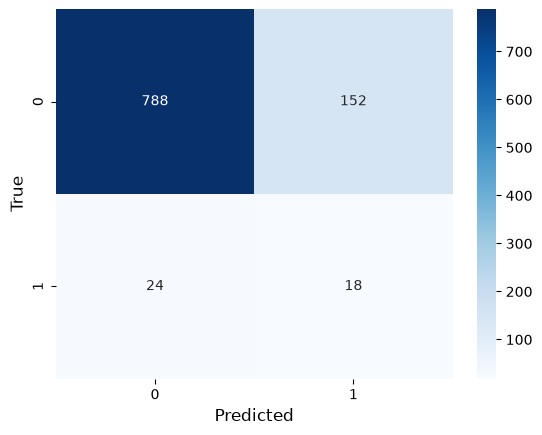

In [40]:
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted', fontsize=12)
plt.ylabel('True', fontsize=12)

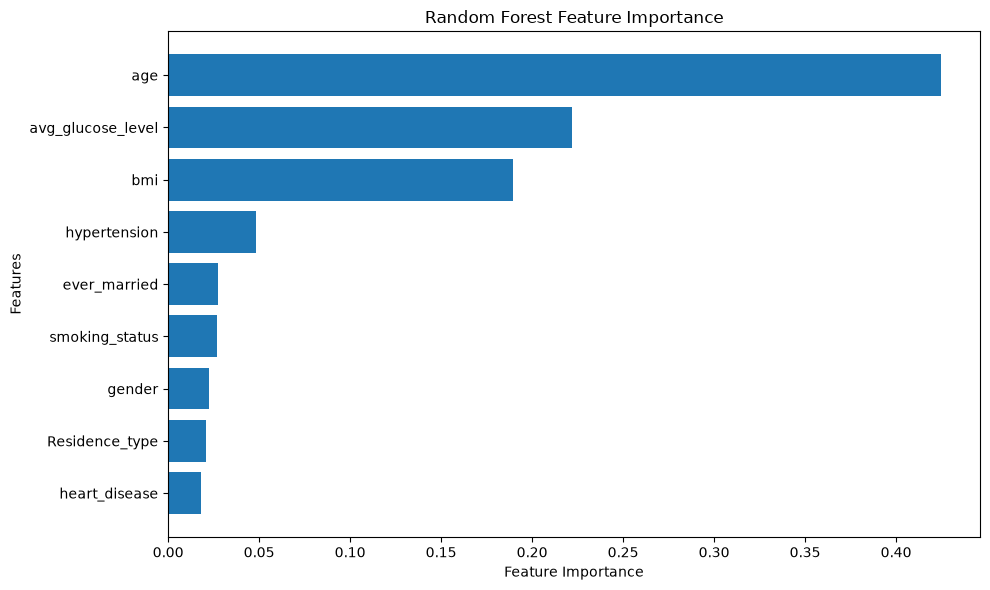

In [41]:
importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(importance.index, importance.values)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()